# Commodity ETF Momentum and Speculative Crowding — Adaptation of Kang et al. (2021)

**Research question:** Does speculative crowding in commodity futures predict subsequent momentum returns for commodity ETFs, and how does a low-crowding-only exposure compare with classical ETF momentum?

| | Classical momentum | Low-crowding momentum |
|---|---|---|
| Ranking signal | Trailing 52-week ETF adjusted-price return | Same momentum ranking |
| Portfolio | Top half long, bottom half short | Same portfolio in low-crowding weeks; zero exposure otherwise |
| Weight | Equal weights in each leg (6 long / 6 short) | Classical weights multiplied by a low-crowding indicator |
| Rebalance | Weekly (Tuesday-to-Tuesday) | Weekly |

**Reference:** Kang, W., Rouwenhorst, K. G., and Tang, K. (2021), *Crowding and Factor Returns*, sections 2–4, equations (2)–(5), Figure 2 and Table 3.


## 1. Research design

1. **Investment universe:** Twelve public Yahoo Finance commodity ETF/ETP price histories, matched to twelve CFTC commodity futures markets. This is the only substitution to the *return series* compared with our preceding futures notebook.
2. **Momentum:** Past 52 observed **weekly ETF returns** without skipping the last month: $MOM_{i,t}=\prod_{k=0}^{51}(1+R_{i,t-k}^{ETF})-1$.
3. **Speculative positioning:** CFTC **Legacy / Futures Only / Non-Commercial** long minus short, divided by open interest, minus the preceding 52-week average (paper equations 2–4). These CFTC measures **still come from futures**, not ETF positions.
4. **Factor crowding:** Equal-weighted signed constituents, with $\tfrac12(\overline C_{long}-\overline C_{short})$ (paper equation 5). **Figure 2** uses the trailing 156-week average; **Table 3** uses the full-sample median for descriptive event-time sorting.
5. **Strategy comparison:** Classical momentum holds the top 6 ETF/ETP longs and bottom 6 shorts each Tuesday. Low-crowding momentum holds the same weights only if crowding is below its preceding 156-week average, with zero exposure otherwise (zero cash return; no transaction or short-borrow costs).
6. **Timing convention:** ETF return Tuesday-to-Tuesday, CFTC positions indexed by **their Tuesday observation date**, as in the article's empirical analysis. The report is generally released after that date, so the result is *descriptive*, not a point-in-time executable backtest.

Sources: [Kang et al. (2021)](https://ssrn.com/abstract=3814952), [CFTC Legacy Futures Only](https://publicreporting.cftc.gov/Commitments-of-Traders/Legacy-Futures-Only/6dca-aqww), [Yahoo Finance](https://finance.yahoo.com/), [skfin course notebooks](https://github.com/schampon/skfin/tree/master/nbs).


## 2. Environment and ETF / CFTC universe


In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
np.random.seed(SEED)
pd.set_option('display.max_columns', 35)
plt.rcParams.update({'figure.figsize': (11, 5), 'axes.grid': True, 'grid.alpha': 0.22})

DATA_DIR = Path('data')
DATA_DIR.mkdir(exist_ok=True)

START_DATE = '2010-01-01'
END_DATE_EXCLUSIVE = '2026-11-01'
N_LONG = N_SHORT = 6
MOMENTUM_LOOKBACK_WEEKS = 52
CROWDING_LOOKBACK_WEEKS = 52
FACTOR_CROWDING_LOOKBACK_WEEKS = 156
COT_AVAIL_LAG_DAYS = 0
COT_MAX_STALENESS_DAYS = 21

MARKET_CODES = {
    'WTI': '067651', 'NATGAS': '023651', 'GASOLINE': '111659',
    'COPPER': '085692', 'CORN': '002602', 'WHEAT': '001602',
    'SOYBEANS': '005602', 'SUGAR': '080732', 'GOLD': '088691',
    'SILVER': '084691', 'PLATINUM': '076651', 'PALLADIUM': '075651',
}
ETF_SYMBOLS = {
    'WTI': 'USO', 'NATGAS': 'UNG', 'GASOLINE': 'UGA',
    'COPPER': 'CPER', 'CORN': 'CORN', 'WHEAT': 'WEAT',
    'SOYBEANS': 'SOYB', 'SUGAR': 'CANE', 'GOLD': 'GLD',
    'SILVER': 'SLV', 'PLATINUM': 'PPLT', 'PALLADIUM': 'PALL',
}
TICKERS = list(MARKET_CODES)
assert len(TICKERS) == 12 and len(set(MARKET_CODES.values())) == 12
assert set(TICKERS) == set(ETF_SYMBOLS)
print('ETF/ETP tickers:', ', '.join(ETF_SYMBOLS[a] for a in TICKERS))
print('CFTC futures markets:', ', '.join(TICKERS))
print('ETF price source: Yahoo Finance (adjusted closing prices)')
print('CFTC report-date offset (days):', COT_AVAIL_LAG_DAYS)


ETF/ETP tickers: USO, UNG, UGA, CPER, CORN, WEAT, SOYB, CANE, GLD, SLV, PPLT, PALL
CFTC futures markets: WTI, NATGAS, GASOLINE, COPPER, CORN, WHEAT, SOYBEANS, SUGAR, GOLD, SILVER, PLATINUM, PALLADIUM
ETF price source: Yahoo Finance (adjusted closing prices)
CFTC report-date offset (days): 0


## 3. Download CFTC Legacy Futures Only positions



In [2]:
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

CFTC_URL = 'https://publicreporting.cftc.gov/resource/6dca-aqww.json'
CFTC_CACHE = DATA_DIR / 'cftc_legacy_futures_only_12_markets_2010_2026.csv'

CORE_FIELDS = {
    'report_date_as_yyyy_mm_dd': 'Date',
    'cftc_contract_market_code': 'MarketCode',
    'commodity_name': 'Commodity',
    'market_and_exchange_names': 'ExchangeMarket',
    'open_interest_all': 'OI',
    'noncomm_positions_long_all': 'Spec_Long',
    'noncomm_positions_short_all': 'Spec_Short',
}

def fetch_cftc(field_map):
    retries = Retry(total=4, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504])
    session = requests.Session()
    session.mount('https://', HTTPAdapter(max_retries=retries))
    quoted_codes = ','.join(f"'{x}'" for x in MARKET_CODES.values())
    result = []
    offset, limit = 0, 5000
    while True:
        params = {
            '$select': ','.join(field_map),
            '$where': (
                f'cftc_contract_market_code IN ({quoted_codes}) '
                f"AND report_date_as_yyyy_mm_dd >= '{START_DATE}T00:00:00' "
                f"AND report_date_as_yyyy_mm_dd < '{END_DATE_EXCLUSIVE}T00:00:00'"
            ),
            '$order': 'report_date_as_yyyy_mm_dd ASC, cftc_contract_market_code ASC',
            '$limit': limit, '$offset': offset,
        }
        response = session.get(CFTC_URL, params=params, timeout=90)
        response.raise_for_status()
        batch = response.json()
        result.extend(batch)
        if len(batch) < limit:
            break
        offset += len(batch)
    if not result:
        raise ValueError('No Legacy Futures Only CFTC observations. Check the API and market codes.')
    frame = pd.DataFrame(result).rename(columns=field_map)
    frame['MarketCode'] = frame['MarketCode'].astype('string').str.zfill(6)
    frame['Asset'] = frame['MarketCode'].map({v: k for k, v in MARKET_CODES.items()})
    frame['Date'] = pd.to_datetime(frame['Date']).dt.tz_localize(None)
    for col in ['OI', 'Spec_Long', 'Spec_Short']:
        frame[col] = pd.to_numeric(frame[col], errors='coerce')
    return frame.sort_values(['Asset', 'Date']).reset_index(drop=True)

if CFTC_CACHE.exists():
    cftc_raw = pd.read_csv(CFTC_CACHE, dtype={'MarketCode': 'string'}, parse_dates=['Date'])
    print('Loaded CFTC cache:', CFTC_CACHE)
else:
    cftc_raw = fetch_cftc(CORE_FIELDS)
    cftc_raw.to_csv(CFTC_CACHE, index=False)
    print('CFTC observations downloaded:', len(cftc_raw))

required_cols = ['Asset', 'Date', 'OI', 'Spec_Long', 'Spec_Short']
if not set(required_cols).issubset(cftc_raw.columns):
    raise ValueError('CFTC cache has the wrong schema; delete the cache and download again.')
missing = sorted(set(TICKERS) - set(cftc_raw['Asset'].dropna()))
if missing:
    raise ValueError(f'Missing CFTC futures markets: {missing}. Review code mappings.')
if cftc_raw.duplicated(['Asset', 'Date']).any():
    duplicates = cftc_raw[cftc_raw.duplicated(['Asset', 'Date'], keep=False)]
    raise ValueError(f'Ambiguous market-code mapping (multiple CFTC rows):\n{duplicates.head(12)}')
coverage = cftc_raw.groupby('Asset').agg(Start=('Date', 'min'), End=('Date', 'max'), N=('Date', 'size'))
display(coverage.reindex(TICKERS))
display(cftc_raw[['Asset', 'MarketCode', 'ExchangeMarket']].drop_duplicates().sort_values('Asset'))


CFTC observations downloaded: 10536


,Start,End,N
Asset,,,
WTI,2010-01-05,2026-10-27,878
NATGAS,2010-01-05,2026-10-27,878
GASOLINE,2010-01-05,2026-10-27,878
COPPER,2010-01-05,2026-10-27,878
CORN,2010-01-05,2026-10-27,878
WHEAT,2010-01-05,2026-10-27,878
SOYBEANS,2010-01-05,2026-10-27,878
SUGAR,2010-01-05,2026-10-27,878
GOLD,2010-01-05,2026-10-27,878


,Asset,MarketCode,ExchangeMarket
0,COPPER,085692,COPPER-GRADE #1 - COMMODITY EXCHANGE INC.
631,COPPER,085692,COPPER- #1 - COMMODITY EXCHANGE INC.
878,CORN,002602,CORN - CHICAGO BOARD OF TRADE
1756,GASOLINE,111659,GASOLINE BLENDSTOCK (RBOB) - NEW YORK MERCANTI...
2387,GASOLINE,111659,GASOLINE RBOB - NEW YORK MERCANTILE EXCHANGE
2634,GOLD,088691,GOLD - COMMODITY EXCHANGE INC.
3512,NATGAS,023651,NATURAL GAS - NEW YORK MERCANTILE EXCHANGE
4143,NATGAS,023651,NAT GAS NYME - NEW YORK MERCANTILE EXCHANGE
4390,PALLADIUM,075651,PALLADIUM - NEW YORK MERCANTILE EXCHANGE
5268,PLATINUM,076651,PLATINUM - NEW YORK MERCANTILE EXCHANGE


## 4. Construct excess speculative pressure — paper equations (2)–(4)

For commodity $i$ and CFTC report week $t$, speculative net pressure is the **Non-Commercial futures-only** net position, scaled by open interest:

$$
NP_{i,t}=\frac{NC^{long}_{i,t}-NC^{short}_{i,t}}{OI_{i,t}}.
$$

The normal level is the average of the **previous** 52 weekly observations:

$$
\overline{NP}^{(52)}_{i,t}=\frac{1}{52}\sum_{k=1}^{52} NP_{i,t-k},
\qquad C_{i,t}=NP_{i,t}-\overline{NP}^{(52)}_{i,t}.
$$

CFTC positions are dated at their Tuesday observation date, following the article. The position report is not yet public on that Tuesday; this convention is used for empirical comparison, not for executable trading.


In [3]:
crowding_data = (
    cftc_raw[['Date', 'Asset', 'OI', 'Spec_Long', 'Spec_Short']]
    .copy().sort_values(['Asset', 'Date'])
)
crowding_data['NetPressure'] = (
    (crowding_data['Spec_Long'] - crowding_data['Spec_Short'])
    / crowding_data['OI'].where(crowding_data['OI'] > 0)
)
crowding_data['HistoricalPressure'] = (
    crowding_data.groupby('Asset')['NetPressure'].transform(
        lambda s: s.shift(1).rolling(
            CROWDING_LOOKBACK_WEEKS,
            min_periods=CROWDING_LOOKBACK_WEEKS
        ).mean()
    )
)
crowding_data['Crowding'] = crowding_data['NetPressure'] - crowding_data['HistoricalPressure']

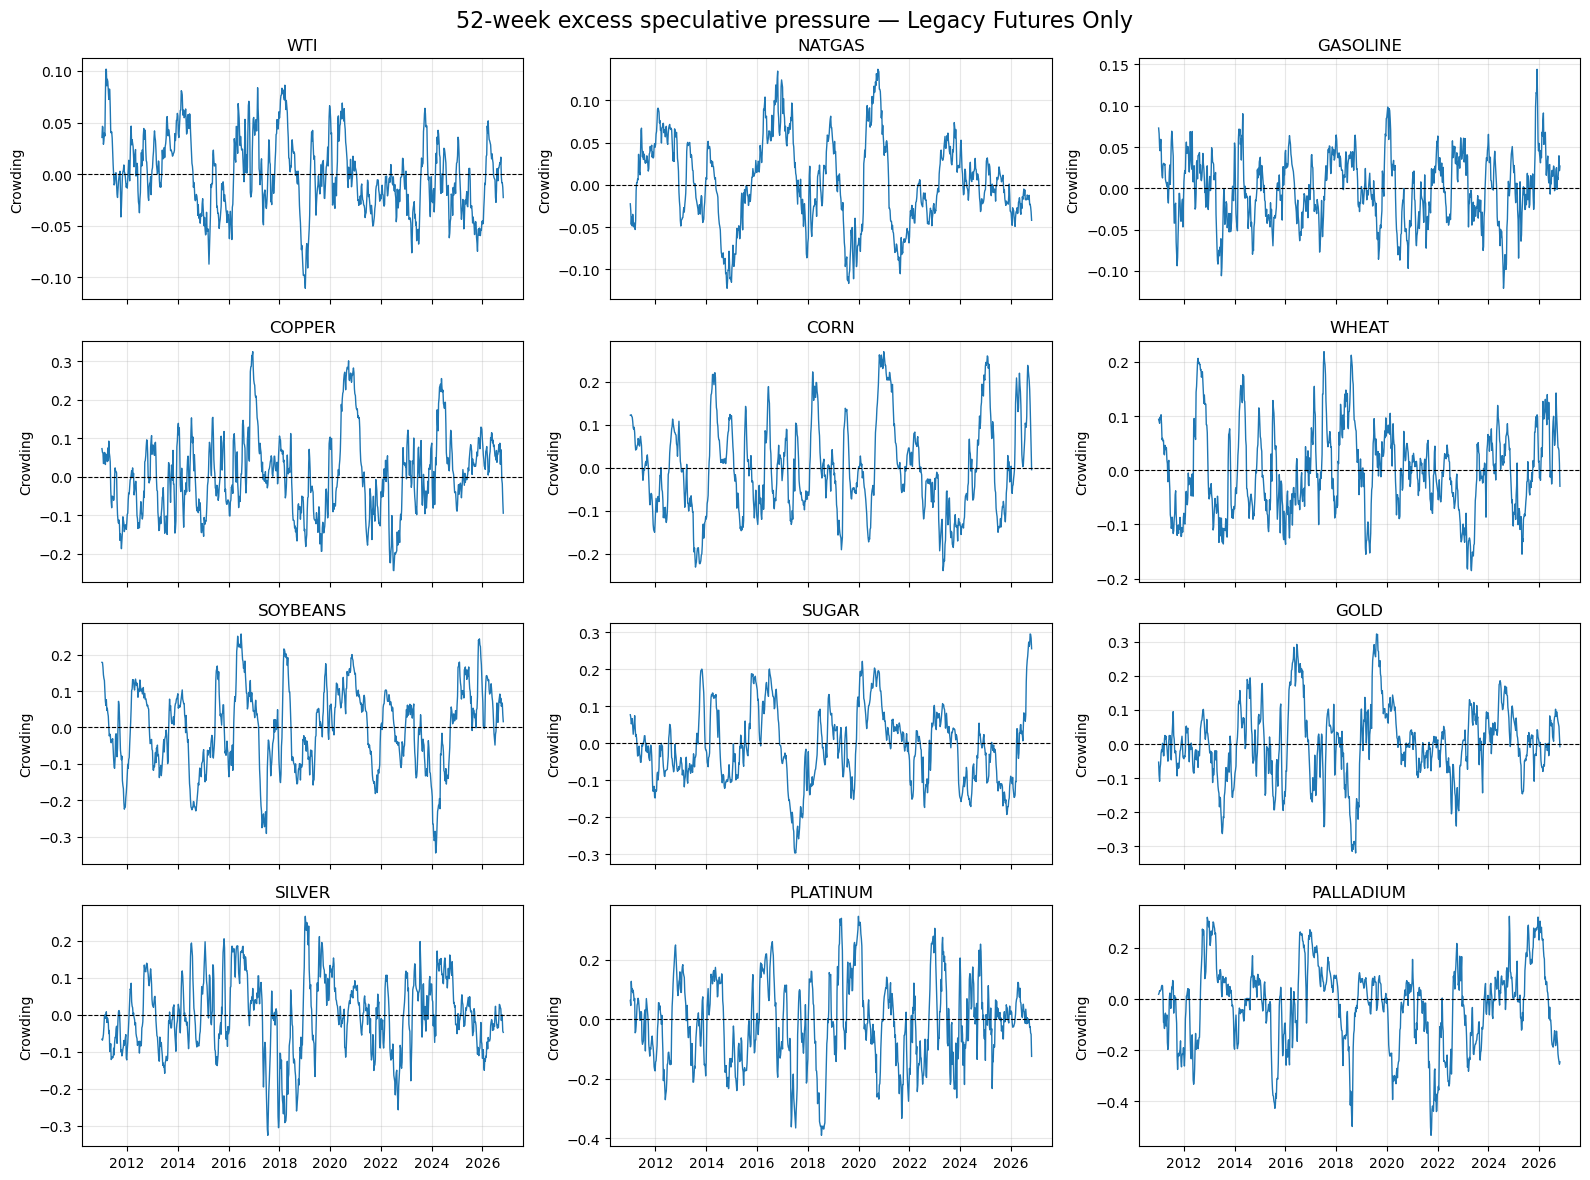

In [4]:
fig, axes = plt.subplots(4, 3, figsize=(16, 12), sharex=True)
axes = axes.flatten()
for ax, asset in zip(axes, TICKERS):
    series = crowding_data.loc[crowding_data['Asset'].eq(asset)].set_index('Date')['Crowding']
    ax.plot(series.index, series, lw=1)
    ax.axhline(0, color='black', linestyle='--', lw=0.8)
    ax.set_title(asset)
    ax.set_ylabel('Crowding')
    ax.grid(alpha=0.3)
fig.suptitle('52-week excess speculative pressure — Legacy Futures Only', fontsize=16)
plt.tight_layout()
plt.show()


## 5. Public Yahoo Finance ETF prices and weekly returns

**Only substitution to the preceding futures notebook:** Download adjusted closing prices of the 12 commodity ETFs/ETPs directly from Yahoo Finance, with `yfinance` (public online source). No manually provided CSV, futures settlements, maturity selection, or roll algorithm is needed.

For the ETF/ETP corresponding to commodity market $i$, weekly return is:

$$
R_{i,t}^{ETF}=\frac{P_{i,t}^{adjusted}}{P_{i,t-1}^{adjusted}}-1.
$$

The Tuesday cadence is unchanged. This **replaces futures-contract excess returns**, so the resulting strategy is an *ETF adaptation* rather than an exact replication of the authors' futures results. ETF/ETP product mechanics can still embed roll yield, management fees, and tracking differences, and short positions can incur borrow costs (not modeled here). A CSV cache is generated *automatically from the download* to avoid repeated queries; nothing must be uploaded or supplied by the user.


Downloaded public Yahoo ETF prices and saved cache: data\yahoo_commodity_etfs_adjusted_daily_12_markets.csv


,ETF,First,Last,Valid days,Valid weeks
WTI,USO,2010-01-04,2026-10-30,4233,878
NATGAS,UNG,2010-01-04,2026-10-30,4233,878
GASOLINE,UGA,2010-01-04,2026-10-30,4233,878
COPPER,CPER,2011-11-15,2026-10-30,3761,781
CORN,CORN,2010-06-09,2026-10-30,4125,855
WHEAT,WEAT,2011-09-19,2026-10-30,3802,789
SOYBEANS,SOYB,2011-09-19,2026-10-30,3802,789
SUGAR,CANE,2011-09-19,2026-10-30,3802,789
GOLD,GLD,2010-01-04,2026-10-30,4233,878
SILVER,SLV,2010-01-04,2026-10-30,4233,878


Weekly Tuesday observations: 2010-01-05 to 2026-10-27


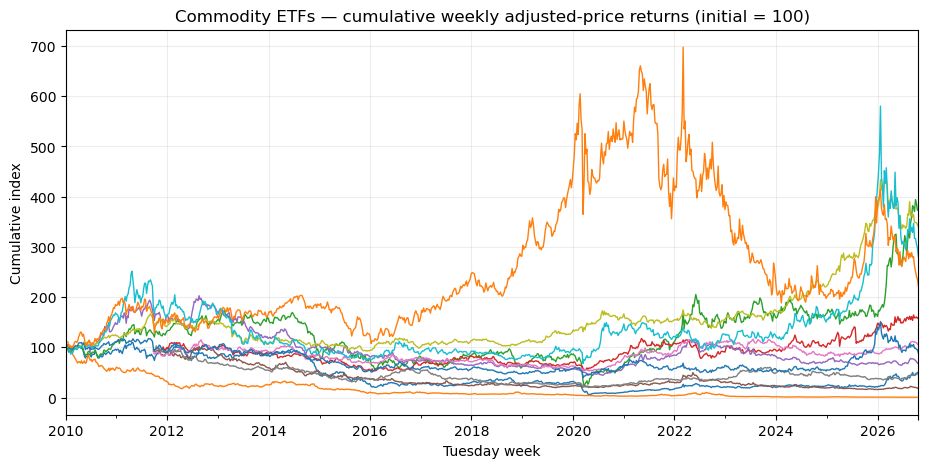

In [5]:
PRICE_CACHE = DATA_DIR / 'yahoo_commodity_etfs_adjusted_daily_12_markets.csv'

if PRICE_CACHE.exists():
    daily_close = pd.read_csv(PRICE_CACHE, index_col=0, parse_dates=True)
    print('Loaded public Yahoo ETF cache:', PRICE_CACHE)
else:
    try:
        import yfinance as yf
    except ImportError as exc:
        raise ImportError('Install the public-data downloader with: pip install yfinance') from exc
    symbols = [ETF_SYMBOLS[asset] for asset in TICKERS]
    raw_prices = yf.download(
        tickers=symbols,
        start=START_DATE,
        end=END_DATE_EXCLUSIVE,
        auto_adjust=True, 
        progress=False,
        group_by='column',
        threads=False,
    )
    if raw_prices.empty:
        raise ValueError('Yahoo Finance returned no ETF prices; check the public data connection.')

    if isinstance(raw_prices.columns, pd.MultiIndex):
        if 'Close' in raw_prices.columns.get_level_values(0):
            daily_close = raw_prices['Close'].copy()
        elif 'Close' in raw_prices.columns.get_level_values(1):
            daily_close = raw_prices.xs('Close', axis=1, level=1).copy()
        else:
            raise ValueError('Yahoo Finance returned no adjusted Close prices.')
    elif len(symbols) == 1 and 'Close' in raw_prices.columns:
        daily_close = raw_prices[['Close']].rename(columns={'Close': symbols[0]})
    else:
        raise ValueError('Unexpected yfinance ETF data shape.')

    daily_close = daily_close.rename(columns={v: k for k, v in ETF_SYMBOLS.items()})
    daily_close.index = pd.to_datetime(daily_close.index).tz_localize(None)
    daily_close = daily_close.sort_index()
    daily_close.to_csv(PRICE_CACHE)
    print('Downloaded public Yahoo ETF prices and saved cache:', PRICE_CACHE)

# Validate the automatically downloaded/cached ETF data.
daily_close = daily_close.sort_index().reindex(columns=TICKERS)
daily_close = daily_close.apply(pd.to_numeric, errors='coerce')
daily_close = daily_close.loc[
    (daily_close.index >= pd.Timestamp(START_DATE))
    & (daily_close.index < pd.Timestamp(END_DATE_EXCLUSIVE))
]
if daily_close.empty:
    raise ValueError('No ETF dates within the requested research period.')
nonpositive = int(daily_close.le(0).sum().sum())
if nonpositive:
    warnings.warn(f'{nonpositive} invalid nonpositive ETF adjusted closes were set to NaN.')
daily_close = daily_close.where(daily_close > 0)

weekly_close = daily_close.resample('W-TUE').last()
weekly_returns = weekly_close.pct_change(fill_method=None)

price_coverage = pd.DataFrame({
    'ETF': pd.Series(ETF_SYMBOLS),
    'First': daily_close.apply(lambda s: s.first_valid_index()),
    'Last': daily_close.apply(lambda s: s.last_valid_index()),
    'Valid days': daily_close.notna().sum(),
    'Valid weeks': weekly_returns.notna().sum(),
}).reindex(TICKERS)
display(price_coverage)
if (weekly_returns.notna().sum() < 200).any():
    raise ValueError(
        'Insufficient ETF history for a 52-week momentum + 156-week regime analysis: '
        + str(weekly_returns.notna().sum().to_dict())
    )

weekly_close = weekly_close.loc[
    weekly_close.index < pd.Timestamp(END_DATE_EXCLUSIVE)
].reindex(columns=TICKERS)
weekly_returns = weekly_returns.reindex(index=weekly_close.index, columns=TICKERS)
print('Weekly Tuesday observations:', weekly_returns.index.min().date(),
      'to', weekly_returns.index.max().date())

fig, ax = plt.subplots()
rebased = (1 + weekly_returns).cumprod() * 100
rebased.plot(ax=ax, lw=1, legend=False)
ax.set(title='Commodity ETFs — cumulative weekly adjusted-price returns (initial = 100)',
       ylabel='Cumulative index', xlabel='Tuesday week')
plt.show()


## 6. Build the **weekly** signal panel

At Tuesday $t$, the momentum ranking is based on the previous 52 **realized weekly ETF returns**, including week $t$. This follows the paper's past-one-year weekly ranking; there is **no 12–1-month convention** here.

$$
MOM_{i,t}=\prod_{k=0}^{51}(1+R_{i,t-k})-1.
$$

Each Tuesday signal is paired with the CFTC positions observed on that Tuesday, using the article's descriptive timing, and evaluated against the **next Tuesday-to-Tuesday return** $R_{i,t+1}$. Only full 12-market weekly cross-sections enter the comparison; the article uses 26 markets. The raw momentum is used for ranking without cross-sectional z-scoring.

**Data substitution:** ETF adjusted-price returns replace the paper's contract-matched futures excess returns.


In [6]:
mom_52w = (
    (1 + weekly_returns).rolling(
        MOMENTUM_LOOKBACK_WEEKS, min_periods=MOMENTUM_LOOKBACK_WEEKS
    ).apply(np.prod, raw=True) - 1
)
next_week_ret = weekly_returns.shift(-1)

def to_series(frame, name):
    return frame.rename_axis(index='Date', columns='Asset').stack(future_stack=True).rename(name)

base_panel = pd.concat([
    to_series(weekly_close, 'Price'),
    to_series(mom_52w, 'Momentum'),
    to_series(next_week_ret, 'NextReturn'),
], axis=1).reset_index().rename(columns={'level_0': 'Date', 'level_1': 'Asset', 'Ticker': 'Asset'})

def build_panel(cot_lag_days):
    crowding_available = crowding_data[
        ['Asset', 'Date', 'NetPressure', 'Crowding']
    ].rename(columns={'Date': 'CFTC_ReportDate'}).copy()
    crowding_available['AvailableAt'] = (
        crowding_available['CFTC_ReportDate'] + pd.Timedelta(days=cot_lag_days)
    )
    frame = pd.merge_asof(
        base_panel.sort_values(['Date', 'Asset']),
        crowding_available.sort_values(['AvailableAt', 'Asset']),
        by='Asset', left_on='Date', right_on='AvailableAt',
        direction='backward', tolerance=pd.Timedelta(days=COT_MAX_STALENESS_DAYS)
    )
    known = frame['AvailableAt'].notna()
    assert (frame.loc[known, 'AvailableAt'] <= frame.loc[known, 'Date']).all()
    assert (frame.loc[known, 'CFTC_ReportDate'] <= frame.loc[known, 'Date']).all()
    frame['ReturnWeek'] = frame['Date'] + pd.Timedelta(days=7)
    needed = ['Momentum', 'Crowding', 'NextReturn']
    counts = frame.dropna(subset=needed).groupby('Date')['Asset'].nunique()
    valid_dates = counts[counts == len(TICKERS)].index
    frame = frame.loc[frame['Date'].isin(valid_dates)].sort_values(['Date', 'Asset']).copy()
    if frame.empty:
        raise ValueError(f'No complete ETF/CFTC weeks for {cot_lag_days}-day lag.')
    assert frame.groupby('Date')['Asset'].nunique().eq(len(TICKERS)).all()
    assert frame[needed].notna().all().all()
    return frame

panel = build_panel(COT_AVAIL_LAG_DAYS)
print(f'{COT_AVAIL_LAG_DAYS}-day lag: {panel.Date.nunique()} usable Tuesdays,',
      panel.Date.min().date(), 'to', panel.Date.max().date())
display(panel[['Date', 'Asset', 'Momentum', 'Crowding', 'CFTC_ReportDate', 'NextReturn']].head(12))

0-day lag: 728 usable Tuesdays, 2012-11-13 to 2026-10-20


,Date,Asset,Momentum,Crowding,CFTC_ReportDate,NextReturn
1788,2012-11-13,COPPER,-0.034154,-0.016086,2012-11-13,0.000000
1789,2012-11-13,CORN,0.088395,0.026376,2012-11-13,0.023887
1790,2012-11-13,GASOLINE,0.173077,-0.022782,2012-11-13,0.024320
1791,2012-11-13,GOLD,-0.036110,0.028509,2012-11-13,0.001735
1792,2012-11-13,NATGAS,-0.297832,0.031209,2012-11-13,0.021798
1793,2012-11-13,PALLADIUM,-0.045891,0.106430,2012-11-13,-0.001598
1794,2012-11-13,PLATINUM,-0.039067,0.096933,2012-11-13,-0.006487
1795,2012-11-13,SILVER,-0.067142,0.078491,2012-11-13,0.022611
1796,2012-11-13,SOYBEANS,0.090287,0.006967,2012-11-13,0.007110
1797,2012-11-13,SUGAR,-0.268080,-0.075931,2012-11-13,0.012493


## 7. Strategy 1 — weekly cross-sectional momentum

Each **Tuesday**, rank the ETFs/ETPs on their **past one-year (52-week) return** (paper section 4.1). With our 12 markets, hold the top **six long** and the bottom **six short**, using the same constant weight within each leg:

$$
w^{MOM}_{i,t}=\begin{cases}+1/6&\text{if }i\text{ is among the six winners},\\-1/6&\text{if }i\text{ is among the six losers}.\end{cases}
$$

The portfolio is dollar-neutral with 200% absolute gross notional. The paper trades **13/13** because its universe has 26 futures (rather than 12 ETF/ETPs); this notebook is a 6/6 sample adaptation.


In [7]:
def six_six_weights(df, score_col):
    scores = df.pivot(index='Date', columns='Asset', values=score_col).reindex(columns=TICKERS)
    if scores.isna().any().any():
        raise ValueError(f'Missing {score_col} in a weekly 6/6 portfolio.')
    ranks = scores.rank(axis=1, method='first', ascending=False)
    weights = pd.DataFrame(-1.0 / N_SHORT, index=scores.index, columns=scores.columns)
    weights[ranks <= N_LONG] = 1.0 / N_LONG
    assert np.allclose(weights.sum(axis=1), 0)
    assert np.allclose(weights.abs().sum(axis=1), 2)
    assert (weights.gt(0).sum(axis=1) == N_LONG).all()
    assert (weights.lt(0).sum(axis=1) == N_SHORT).all()
    return weights

all_classic_weights = six_six_weights(panel, 'Momentum')
display(all_classic_weights.tail(4).style.format('{:+.1%}'))


Asset,WTI,NATGAS,GASOLINE,COPPER,CORN,WHEAT,SOYBEANS,SUGAR,GOLD,SILVER,PLATINUM,PALLADIUM
Date,,,,,,,,,,,,
2026-09-29 00:00:00,+16.7%,-16.7%,+16.7%,+16.7%,-16.7%,+16.7%,+16.7%,-16.7%,-16.7%,+16.7%,-16.7%,-16.7%
2026-10-06 00:00:00,+16.7%,-16.7%,+16.7%,+16.7%,-16.7%,+16.7%,+16.7%,-16.7%,-16.7%,+16.7%,-16.7%,-16.7%
2026-10-13 00:00:00,+16.7%,-16.7%,+16.7%,+16.7%,-16.7%,+16.7%,+16.7%,+16.7%,-16.7%,-16.7%,-16.7%,-16.7%
2026-10-20 00:00:00,+16.7%,-16.7%,+16.7%,+16.7%,-16.7%,-16.7%,+16.7%,+16.7%,-16.7%,+16.7%,-16.7%,-16.7%


## 8. Portfolio-level crowding and the **156-week** regimes

The paper defines signed *factor crowding* (equation 5) from the momentum-factor holdings:

$$
C_t^{MOM}=\tfrac12\left(\overline{C}_{long,t}-\overline{C}_{short,t}\right)
=\tfrac12\sum_i w_{i,t}^{MOM}C_{i,t}.
$$

For **Figure 2**, the paper classifies high and low crowding relative to the preceding three-year (**156-week**) factor-crowding moving average:

$$
\overline C_t^{MOM,(156)}=\frac{1}{156}\sum_{k=1}^{156}C_{t-k}^{MOM}.
$$

For **Table 3**, the paper instead uses the full-sample median of factor crowding at portfolio formation, then examines cumulative post-formation momentum returns through week 13. This full-sample sorting is descriptive and is not a live trading rule.


To compare the classical momentum portfolio with its **low-crowding component** (Figure 2), use the same weekly momentum weights only when factor crowding is below its preceding 156-week mean:

$$
w^{LOW}_{i,t}=w^{MOM}_{i,t}\mathbf{1}_{\{C_t^{MOM}<\overline C_t^{MOM,(156)}\}}.
$$

This equals the paper's low-crowding return decomposition before costs, if zero exposure earns zero return. Treating it as a standalone strategy is an additional illustration, not a trading rule formally implemented and evaluated by the authors.


Evaluated realized weeks: 2015-11-17 to 2026-10-27
Number of weeks with three-year crowding history: 572
Low-crowding share (Figure 2): 50.9%


,FactorCrowding,Past156WeekAverage,LowCrowding
2026-08-18,-0.012344,0.016855,True
2026-08-25,-0.014679,0.016855,True
2026-09-01,-0.001111,0.016568,True
2026-09-08,-0.022246,0.016257,True
2026-09-15,-0.030840,0.015798,True
2026-09-22,-0.007775,0.015307,True
2026-09-29,-0.008902,0.014992,True
2026-10-06,-0.009210,0.014812,True
2026-10-13,0.049517,0.014552,False
2026-10-20,0.039878,0.014635,False


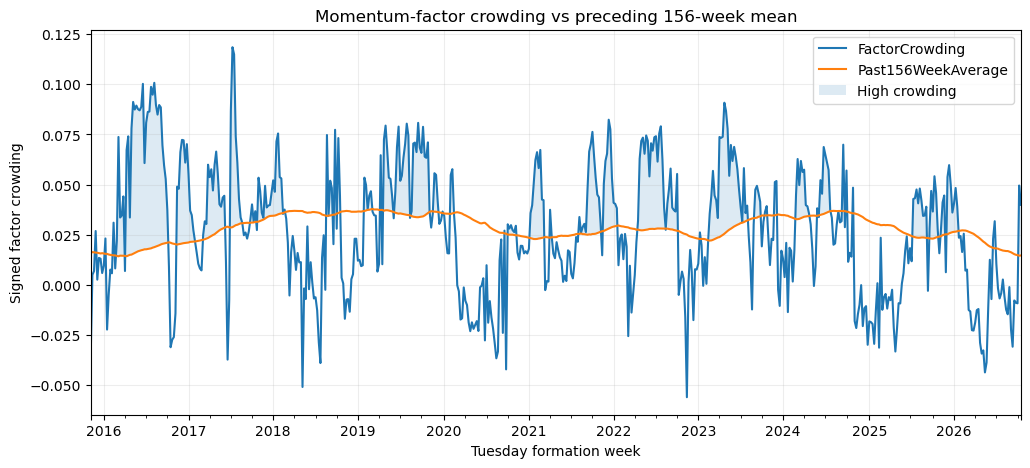

,Momentum,CommodityCrowding,MomentumWeight,LowCrowdingWeight
Asset,,,,
WTI,1.3526,-0.0128,0.1667,0.0
GASOLINE,1.2993,0.0214,0.1667,0.0
COPPER,0.3016,-0.0622,0.1667,0.0
SUGAR,0.2613,0.2844,0.1667,0.0
SOYBEANS,0.2125,0.0357,0.1667,0.0
SILVER,0.1902,-0.0442,0.1667,0.0
WHEAT,0.1687,0.0121,-0.1667,-0.0
PLATINUM,0.0651,-0.0501,-0.1667,-0.0
CORN,0.0229,0.0469,-0.1667,-0.0


In [8]:
def build_factor_regime(signal_panel, classic_weights):
    crowding_wide = (
        signal_panel.pivot(index='Date', columns='Asset', values='Crowding')
        .reindex(index=classic_weights.index, columns=classic_weights.columns)
    )
    assert crowding_wide.notna().all().all()
    factor = 0.5 * (classic_weights * crowding_wide).sum(axis=1)
    factor.name = 'FactorCrowding'
    full_week_index = pd.date_range(factor.index.min(), factor.index.max(), freq='W-TUE')
    factor = factor.reindex(full_week_index)
    threshold = factor.shift(1).rolling(
        FACTOR_CROWDING_LOOKBACK_WEEKS,
        min_periods=FACTOR_CROWDING_LOOKBACK_WEEKS
    ).mean()
    threshold.name = 'Past156WeekAverage'
    dates = threshold.dropna().index.intersection(classic_weights.index)
    return factor, threshold, dates

factor_crowding, factor_crowding_threshold, signal_dates = build_factor_regime(
    panel, all_classic_weights
)
if signal_dates.empty:
    raise ValueError('No weeks with 156 prior crowding observations.')

low_crowding = factor_crowding.lt(factor_crowding_threshold).loc[signal_dates]
low_crowding.name = 'LowCrowding'
sample = panel.loc[panel['Date'].isin(signal_dates)].copy()
w_momentum = all_classic_weights.loc[signal_dates]
w_low_crowding = w_momentum.mul(low_crowding.astype(float), axis=0)
assert np.allclose(w_low_crowding.loc[low_crowding], w_momentum.loc[low_crowding])
assert np.allclose(w_low_crowding.loc[~low_crowding], 0.0)

print('Evaluated realized weeks:', sample.ReturnWeek.min().date(), 'to', sample.ReturnWeek.max().date())
print('Number of weeks with three-year crowding history:', len(signal_dates))
print('Low-crowding share (Figure 2):', f'{low_crowding.mean():.1%}')

regimes = pd.DataFrame({
    'FactorCrowding': factor_crowding.loc[signal_dates],
    'Past156WeekAverage': factor_crowding_threshold.loc[signal_dates],
    'LowCrowding': low_crowding,
})
display(regimes.tail(10))

fig, ax = plt.subplots(figsize=(12, 5))
regimes[['FactorCrowding', 'Past156WeekAverage']].plot(ax=ax, lw=1.5)
ax.fill_between(regimes.index, regimes['FactorCrowding'], regimes['Past156WeekAverage'],
                where=~regimes['LowCrowding'], alpha=0.15, label='High crowding')
ax.set(title='Momentum-factor crowding vs preceding 156-week mean',
       ylabel='Signed factor crowding', xlabel='Tuesday formation week')
ax.legend()
plt.show()

example_date = signal_dates[-1]
example = sample.loc[sample['Date'].eq(example_date)].set_index('Asset')
display(pd.DataFrame({
    'Momentum': example['Momentum'],
    'CommodityCrowding': example['Crowding'],
    'MomentumWeight': w_momentum.loc[example_date],
    'LowCrowdingWeight': w_low_crowding.loc[example_date],
}).sort_values('Momentum', ascending=False).round(4))

## 9. Weekly ETF momentum-factor returns

For the portfolio formed on Tuesday $t$, calculate the next-week **gross ETF return**:

$$
R_{t+1}^{MOM}=\sum_i w_{i,t}^{MOM}R_{i,t+1}.
$$


In [9]:
def backtest(weights, observations):
    realized = observations.pivot(index='Date', columns='Asset', values='NextReturn')
    realized = realized.reindex(index=weights.index, columns=weights.columns)
    if realized.isna().any().any():
        raise ValueError('Missing next-week ETF returns in the evaluated sample.')
    gross = (weights * realized).sum(axis=1)
    result = pd.DataFrame({'GrossReturn': gross})
    result.index = result.index + pd.Timedelta(days=7)
    result.index.name = 'ReturnWeek'
    return result

def performance_metrics(bt, active=None):
    ret = bt['GrossReturn'].dropna()
    if ret.empty:
        return pd.Series(dtype=float)
    wealth = (1 + ret).cumprod()
    drawdown = pd.concat([pd.Series([1.0]), wealth.reset_index(drop=True)], ignore_index=True)
    drawdown = drawdown / drawdown.cummax() - 1
    annual_return = float(wealth.iloc[-1]) ** (52 / len(ret)) - 1 if wealth.iloc[-1] > 0 else np.nan
    vol = ret.std(ddof=1) * np.sqrt(52)
    active_returns = ret if active is None else ret.loc[active.reindex(ret.index).fillna(False)]
    return pd.Series({
        'Annual return': annual_return,
        'Annual volatility': vol,
        'Sharpe (rf=0)': (ret.mean() * np.sqrt(52) / ret.std(ddof=1)) if vol > 0 else np.nan,
        'Maximum drawdown': drawdown.min(),
        'Positive active weeks': active_returns.gt(0).mean() if len(active_returns) else np.nan,
        'Active share': len(active_returns) / len(ret),
    })

bt_momentum = backtest(w_momentum, sample)
bt_low_crowding = backtest(w_low_crowding, sample)
assert bt_momentum.index.equals(bt_low_crowding.index)
assert np.allclose(
    bt_low_crowding['GrossReturn'].to_numpy(),
    bt_momentum['GrossReturn'].to_numpy() * low_crowding.loc[signal_dates].to_numpy(dtype=float)
)
print('FULL-AVAILABLE-SAMPLE WEEKLY MOMENTUM COMPARISON — TUESDAY REPORT DATING')
active_low = low_crowding.loc[signal_dates].set_axis(bt_low_crowding.index)
metrics = pd.DataFrame({
    'Classical momentum': performance_metrics(bt_momentum),
    'Low-crowding momentum': performance_metrics(bt_low_crowding, active=active_low),
}).T
display(metrics.round(4))

FULL-AVAILABLE-SAMPLE WEEKLY MOMENTUM COMPARISON — TUESDAY REPORT DATING


,Annual return,Annual volatility,Sharpe (rf=0),Maximum drawdown,Positive active weeks,Active share
Classical momentum,0.0300,0.2052,0.2467,-0.3366,0.5245,1.0000
Low-crowding momentum,0.0476,0.1525,0.3812,-0.2384,0.5567,0.5087


## 10. Momentum-factor returns and crowding regimes

**Figure 2** decomposes the same weekly-rebalanced ETF momentum-factor returns according to low/high crowding defined with the preceding 156-week average. **Table 3** examines returns for up to 13 weeks after factor formation, conditional on a full-sample median split. These analyses use the Tuesday observation convention of Kang et al. (2021).

The two portfolio wealth paths below compare **classical momentum** and the **low-crowding-only** portfolio over identical realized weeks; Figure 2 and Table 3 remain separate diagnostics.

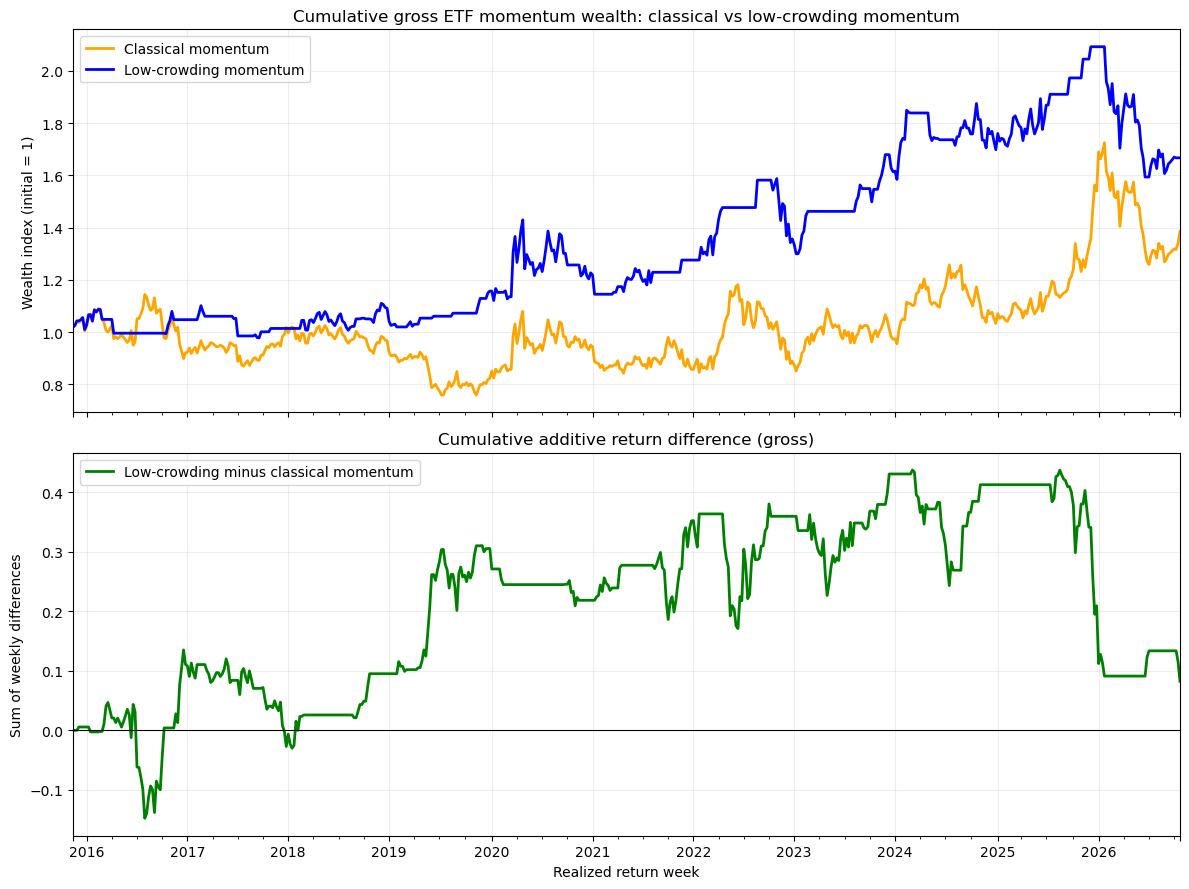

In [10]:

returns = pd.concat({
    'Classical momentum': bt_momentum.GrossReturn,
    'Low-crowding momentum': bt_low_crowding.GrossReturn,
}, axis=1)

start_week = returns.index[0] - pd.Timedelta(days=7)
wealth = (1 + returns).cumprod()
wealth.loc[start_week] = 1.0
wealth = wealth.sort_index()

fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

wealth['Classical momentum'].plot(
    ax=axes[0], lw=2, color='orange', label='Classical momentum'
)
wealth['Low-crowding momentum'].plot(
    ax=axes[0], lw=2, color='blue', label='Low-crowding momentum'
)

axes[0].set(
    title='Cumulative gross ETF momentum wealth: classical vs low-crowding momentum',
    ylabel='Wealth index (initial = 1)'
)
axes[0].legend()


(returns['Low-crowding momentum'] - returns['Classical momentum']).cumsum().plot(
    ax=axes[1],
    lw=2,
    color='green',
    label='Low-crowding minus classical momentum'
)

axes[1].axhline(0, color='black', lw=0.8)
axes[1].set(
    title='Cumulative additive return difference (gross)',
    ylabel='Sum of weekly differences',
    xlabel='Realized return week'
)
axes[1].legend()

plt.tight_layout()
plt.show()


,Weeks,AvgMomentumWeeklyReturn,TotalMomentumReturn,AvgLowCrowdingWeeklyReturn,TotalLowCrowdingReturn
Regime,,,,,
High Crowding,281,-0.029,-8.259,0.00,0.00
Low Crowding,291,0.220,63.930,0.22,63.93


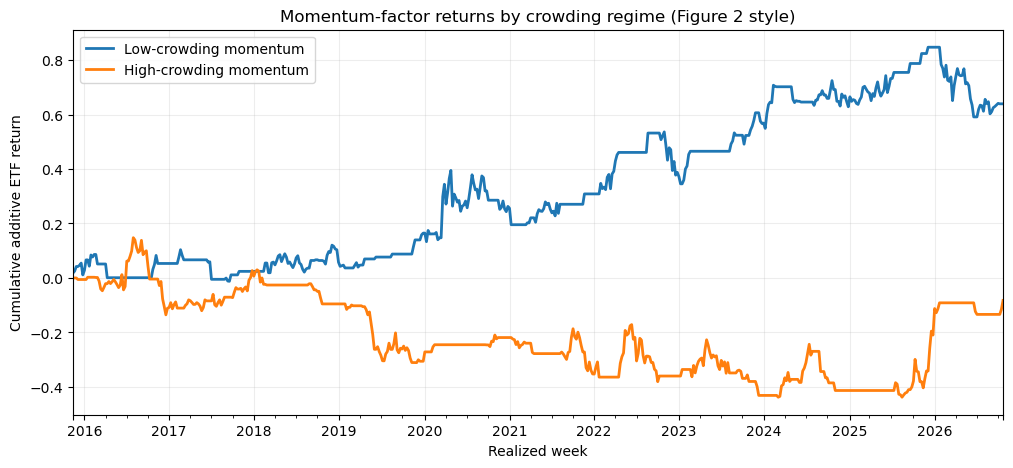

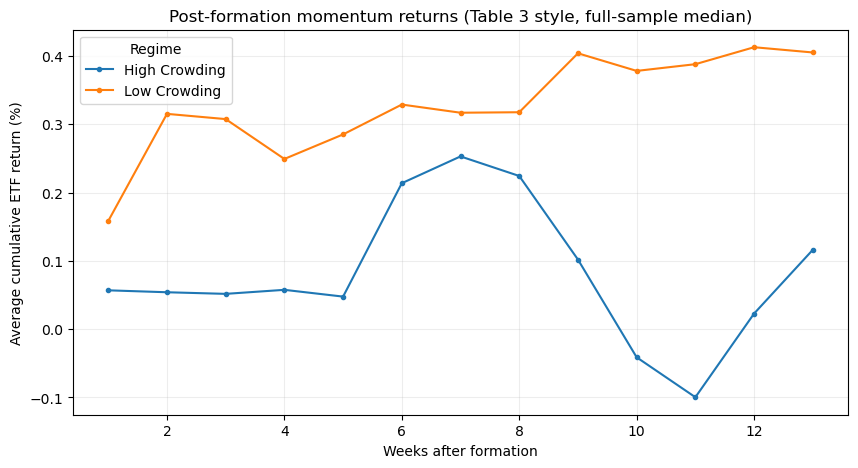

Regime,High Crowding,Low Crowding
WeeksAhead,,
1,0.057,0.158
4,0.058,0.249
13,0.116,0.405


Classical vs low-crowding ETF momentum — full available sample (gross, Tuesday reporting convention)


,Gross Sharpe (52-week annualized),Final gross wealth
Classical momentum,0.247,1.384
Low-crowding momentum,0.381,1.667


In [11]:
regime_flag = low_crowding.loc[signal_dates].to_numpy(dtype=bool)
diagnostic = pd.DataFrame({
    'Regime': np.where(regime_flag, 'Low Crowding', 'High Crowding'),
    'MomentumGross': bt_momentum['GrossReturn'].to_numpy(),
    'LowCrowdingGross': bt_low_crowding['GrossReturn'].to_numpy(),
}, index=bt_momentum.index)
summary = diagnostic.groupby('Regime').agg(
    Weeks=('MomentumGross', 'size'),
    AvgMomentumWeeklyReturn=('MomentumGross', 'mean'),
    TotalMomentumReturn=('MomentumGross', 'sum'),
    AvgLowCrowdingWeeklyReturn=('LowCrowdingGross', 'mean'),
    TotalLowCrowdingReturn=('LowCrowdingGross', 'sum'),
)
summary[summary.columns.drop('Weeks')] *= 100
display(summary.round(3))

regime_pnl = pd.DataFrame({
    'Low-crowding momentum': bt_momentum.GrossReturn.where(regime_flag, 0.0),
    'High-crowding momentum': bt_momentum.GrossReturn.where(~regime_flag, 0.0),
})
fig, ax = plt.subplots(figsize=(12, 5))
regime_pnl.cumsum().plot(ax=ax, lw=2)
ax.set(title='Momentum-factor returns by crowding regime (Figure 2 style)',
       ylabel='Cumulative additive ETF return', xlabel='Realized week')
plt.show()

full_sample_median = factor_crowding.median()
future = weekly_returns.reindex(columns=TICKERS)
formation = []
for date in all_classic_weights.index:
    loc = future.index.get_indexer([date])[0]
    if loc < 0:
        continue
    next_13 = future.iloc[loc + 1:loc + 14]
    if len(next_13) != 13 or next_13.isna().any().any():
        continue
    fixed_weights = all_classic_weights.loc[date].reindex(TICKERS).to_numpy(dtype=float)
    cumulative_return = np.cumsum(next_13.to_numpy(dtype=float) @ fixed_weights)
    for week_ahead, value in enumerate(cumulative_return, start=1):
        formation.append({
            'Formation': date,
            'Regime': 'Low Crowding' if factor_crowding.loc[date] < full_sample_median else 'High Crowding',
            'WeeksAhead': week_ahead,
            'CumulativeReturn': value,
        })
if formation:
    event_study = pd.DataFrame(formation)
    event_means = event_study.groupby(['WeeksAhead', 'Regime'])['CumulativeReturn'].mean().unstack()
    fig, ax = plt.subplots(figsize=(10, 5))
    (100 * event_means).plot(ax=ax, marker='o', markersize=3)
    ax.set(title='Post-formation momentum returns (Table 3 style, full-sample median)',
           ylabel='Average cumulative ETF return (%)', xlabel='Weeks after formation')
    plt.show()
    display((100 * event_means.loc[[1, 4, 13]]).round(3))
else:
    print('Insufficient fully observed 13-week forward windows for event-time analysis.')

def sharpe(returns):
    vol = returns.std(ddof=1)
    return np.sqrt(52) * returns.mean() / vol if vol > 0 else np.nan
sharpe_summary = pd.DataFrame({
    'Gross Sharpe (52-week annualized)': {
        'Classical momentum': sharpe(bt_momentum.GrossReturn),
        'Low-crowding momentum': sharpe(bt_low_crowding.GrossReturn),
    },
    'Final gross wealth': {
        'Classical momentum': wealth['Classical momentum'].iloc[-1],
        'Low-crowding momentum': wealth['Low-crowding momentum'].iloc[-1],
    },
})
print('Classical vs low-crowding ETF momentum — full available sample (gross, Tuesday reporting convention)')
display(sharpe_summary.round(3))